# Day 01 — First K-Means Clustering Experiment

Unsupervised clustering of 2-D synthetic data with K-Means.

- **Data:** 400 points generated with `make_blobs` (4 true centers, `cluster_std=1.2`)
- **Models:** K = 3 and K = 4
- **Metric:** Inertia (within-cluster sum of squared distances)

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Generate 400 points from 4 clusters
X, y_true = make_blobs(
    n_samples=400,
    centers=4,
    cluster_std=1.2,
    random_state=42,
)

print(f"Data shape: {X.shape}")

Data shape: (400, 2)


## K = 3

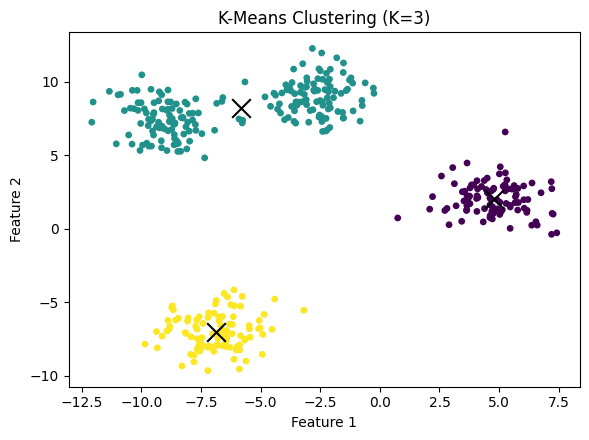

Centers: [[ 4.76854828  2.01807919]
 [-5.80271369  8.22153737]
 [-6.88472071 -7.00475906]]
Inertia (K=3): 3218.6613624115


In [2]:
model_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)
y_pred_k3 = model_k3.fit_predict(X)

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y_pred_k3, s=15)
plt.scatter(
    model_k3.cluster_centers_[:, 0],
    model_k3.cluster_centers_[:, 1],
    marker="x",
    s=180,
    c="black",
)
plt.title("K-Means Clustering (K=3)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.savefig("figures/kmeans_k3.png", dpi=150)
plt.show()

print("Centers:", model_k3.cluster_centers_)
print("Inertia (K=3):", model_k3.inertia_)

## K = 4

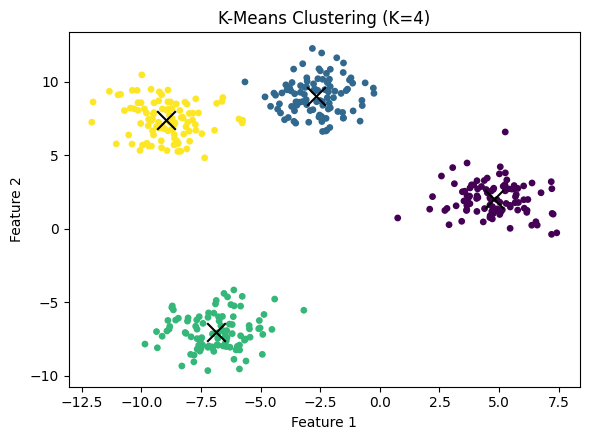

Centers: [[ 4.76854828  2.01807919]
 [-2.65803969  9.04942651]
 [-6.88472071 -7.00475906]
 [-8.9473877   7.39364823]]
Inertia (K=4): 1103.7863583130052


In [3]:
model_k4 = KMeans(n_clusters=4, random_state=42, n_init=10)
y_pred_k4 = model_k4.fit_predict(X)

plt.figure(figsize=(6, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y_pred_k4, s=15)
plt.scatter(
    model_k4.cluster_centers_[:, 0],
    model_k4.cluster_centers_[:, 1],
    marker="x",
    s=180,
    c="black",
)
plt.title("K-Means Clustering (K=4)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.savefig("figures/kmeans_k4.png", dpi=150)
plt.show()

print("Centers:", model_k4.cluster_centers_)
print("Inertia (K=4):", model_k4.inertia_)

## Observation

K=3 has a larger inertia than K=4. Inertia is the sum of squared distances between each point and its assigned centroid, and K-Means minimizes this quantity. With one extra centroid, K=4 has more flexibility: points that were far from their K=3 centroid can be assigned to a closer center, so the total distance can only decrease or stay the same. Since the data were generated from four clusters, K=3 must merge two of them, leaving large within-cluster distances. K=4 matches the true structure much better, which explains the large drop in inertia. However, lower inertia alone cannot prove that a model is better — inertia generally decreases as K grows.